In [13]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import sys
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path('/content/drive/MyDrive/pizza_rl_pj')
sys.path.insert(0, str(PROJECT_DIR))

from pizza_env_stage3 import PizzaKitchenStage3Env

print('Project directory:', PROJECT_DIR)
print('Environment file exists:', (PROJECT_DIR / 'pizza_env_stage3.py').exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/pizza_rl_pj
Environment file exists: True


In [14]:
def train_stage3(
    episodes=50_000,
    seed=42,
    alpha=0.1,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay=0.9999,
    log_every=10_000,
):
    """
    Sparse tabular Q-learning for Stage 3.
    Only visited states are stored in the dictionary.
    """
    env = PizzaKitchenStage3Env(
        n_orders=4,
        min_deadline=6,
        max_deadline=16,
        observation_mode="discrete",
    )

    rng = np.random.default_rng(seed)
    q = {}
    history = []
    epsilon = epsilon_start

    print("--- Stage 3 Q-Learning training started ---")
    print("State space:", env.observation_space.n)
    print("Action space:", env.action_space.n)
    print("Episodes:", episodes)

    for episode in range(1, episodes + 1):
        state, _ = env.reset(seed=seed + episode)
        total_reward = 0.0
        done = False

        while not done:
            if state not in q:
                q[state] = np.zeros(env.action_space.n, dtype=np.float32)

            if rng.random() < epsilon:
                action = int(rng.integers(env.action_space.n))
            else:
                action = int(np.argmax(q[state]))

            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            if next_state not in q:
                q[next_state] = np.zeros(env.action_space.n, dtype=np.float32)

            if done:
                target = reward
            else:
                target = reward + gamma * float(np.max(q[next_state]))

            q[state][action] += alpha * (target - q[state][action])

            state = next_state
            total_reward += reward

        epsilon = max(epsilon_end, epsilon * epsilon_decay)

        history.append({
            "episode": episode,
            "reward": total_reward,
            "served": info["served"],
            "expired": info["expired"],
            "wrong_serves": info["wrong_serves"],
            "steps": info["steps"],
            "epsilon": epsilon,
            "visited_states": len(q),
        })

        if episode % log_every == 0:
            recent = history[-log_every:]
            avg_reward = np.mean([x["reward"] for x in recent])
            avg_served = np.mean([x["served"] for x in recent])
            print(
                f"Episode {episode}/{episodes} | "
                f"Avg Reward: {avg_reward:.2f} | "
                f"Avg Served: {avg_served:.2f} | "
                f"Visited States: {len(q):,}"
            )

    env.close()
    print("--- Stage 3 training completed ---")
    print("Visited states:", f"{len(q):,}")

    return q, history

In [ ]:
def evaluate_stage3(q, episodes=1_000, seed=10_000):
    env = PizzaKitchenStage3Env(
        n_orders=4,
        min_deadline=6,
        max_deadline=16,
        observation_mode="discrete",
    )

    results = []

    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        done = False
        total_reward = 0.0

        while not done:
            q_values = q.get(
                state,
                np.zeros(env.action_space.n, dtype=np.float32),
            )
            action = int(np.argmax(q_values))

            state, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            done = terminated or truncated

        results.append({
            "episode": episode + 1,
            "return": total_reward,
            "served": info["served"],
            "expired": info["expired"],
            "wrong_serves": info["wrong_serves"],
            "steps": info["steps"],
        })

    env.close()

    performance = {
        "Average Reward (Return)": float(
            np.mean([x["return"] for x in results])
        ),
        "Order Completion Rate (%)": float(
            np.mean([x["served"] / 4 * 100 for x in results])
        ),
        "Average Served Orders (Max 4)": float(
            np.mean([x["served"] for x in results])
        ),
        "Average Expired Orders": float(
            np.mean([x["expired"] for x in results])
        ),
        "Average Wrong Serves": float(
            np.mean([x["wrong_serves"] for x in results])
        ),
        "Average Steps per Episode": float(
            np.mean([x["steps"] for x in results])
        ),
    }

    return performance, results

In [15]:
def save_stage3_results(q, history, performance, evaluation_results):
    output_dir = Path(
        "/content/drive/MyDrive/pizza_rl_pj/results_stage3"
    )
    output_dir.mkdir(parents=True, exist_ok=True)

    # Sparse Q-table: state IDs and corresponding 7 action values.
    states = np.asarray(list(q.keys()), dtype=np.int64)
    values = (
        np.stack([q[state] for state in states]).astype(np.float32)
        if len(states)
        else np.empty((0, 7), dtype=np.float32)
    )

    np.savez_compressed(
        output_dir / "q_table_stage3.npz",
        states=states,
        values=values,
    )

    history_path = output_dir / "q_learning_history_stage3.csv"
    with history_path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=list(history[0].keys()))
        writer.writeheader()
        writer.writerows(history)

    evaluation_path = output_dir / "test_performance_stage3.csv"
    with evaluation_path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(
            f, fieldnames=list(evaluation_results[0].keys())
        )
        writer.writeheader()
        writer.writerows(evaluation_results)

    performance_path = output_dir / "performance_summary_stage3.csv"
    with performance_path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.writer(f)
        writer.writerow(["Metric", "Value"])
        writer.writerows(performance.items())

    print("Saved results to:", output_dir)
    return output_dir

In [16]:
q, history = train_stage3(
    episodes=50_000,
    seed=42,
    alpha=0.1,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay=0.9999,
)

performance, evaluation_results = evaluate_stage3(
    q,
    episodes=1_000,
    seed=10_000,
)

print('\n--- Stage 3 Evaluation ---')
for metric, value in performance.items():
    print(f'{metric}: {value:.2f}')

output_dir = save_stage3_results(q, history, performance, evaluation_results)

--- Stage 3 Q-Learning training started ---
State space: 1670420000
Action space: 7
Episodes: 50000
Episode 10000/50000 | Avg Reward: -56.44 | Avg Served: 0.12 | Visited States: 108,778
Episode 20000/50000 | Avg Reward: -43.12 | Avg Served: 0.23 | Visited States: 208,068
Episode 30000/50000 | Avg Reward: -34.78 | Avg Served: 0.38 | Visited States: 304,433
Episode 40000/50000 | Avg Reward: -30.57 | Avg Served: 0.48 | Visited States: 399,146
Episode 50000/50000 | Avg Reward: -29.29 | Avg Served: 0.53 | Visited States: 492,050
--- Stage 3 training completed ---
Visited states: 492,050

--- Stage 3 Evaluation ---
Average Reward (Return): -26.03
Order Completion Rate (%): 17.05
Average Served Orders (Max 4): 0.68
Average Expired Orders: 3.32
Average Wrong Serves: 0.07
Average Steps per Episode: 13.96
Saved results to: /content/drive/MyDrive/pizza_rl_pj/results_stage3


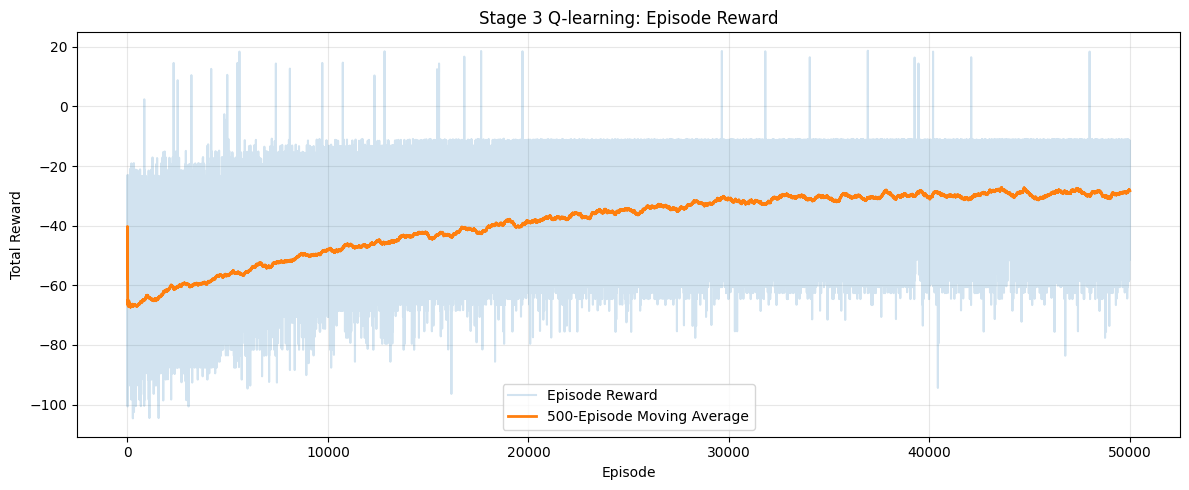

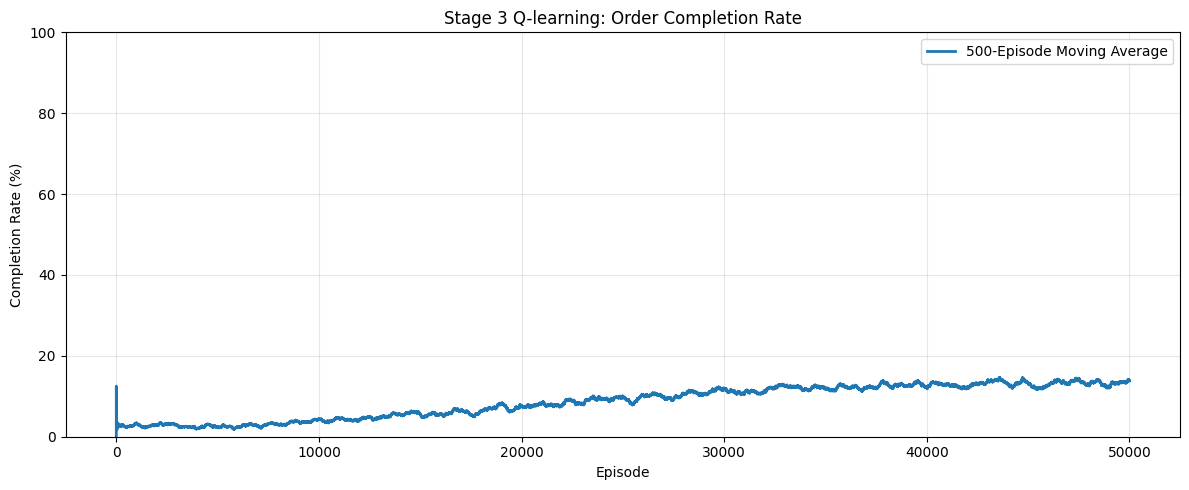

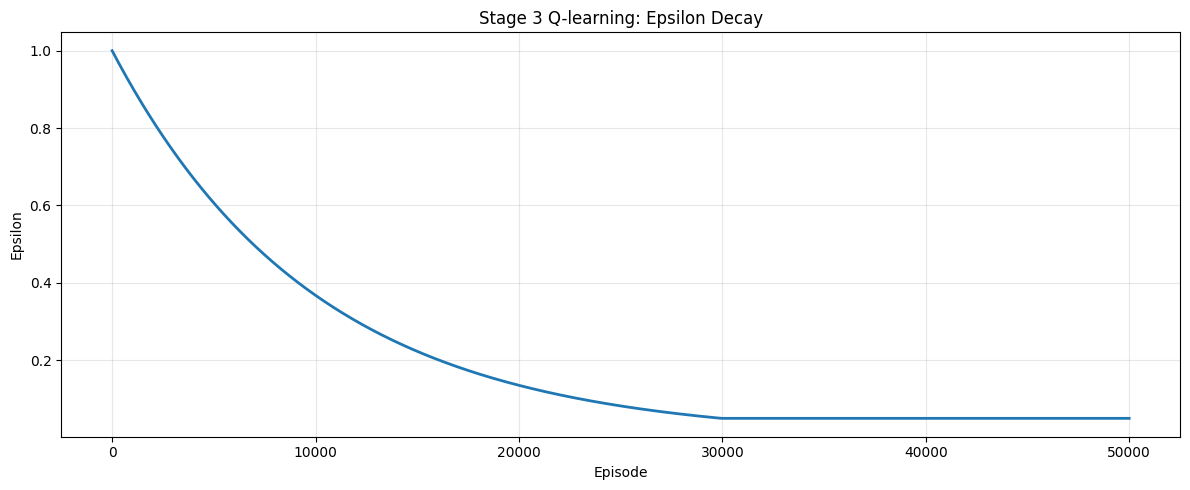

Graph data saved to: /content/drive/MyDrive/pizza_rl_pj/results_stage3/training_graph_data_stage3.csv


In [17]:
history_df = pd.DataFrame(history)
WINDOW = 500

history_df['moving_avg_reward'] = history_df['reward'].rolling(WINDOW, min_periods=1).mean()
history_df['completion_rate'] = history_df['served'] / 4 * 100
history_df['moving_avg_completion'] = history_df['completion_rate'].rolling(WINDOW, min_periods=1).mean()

# 1) 에피소드별 누적 보상과 이동 평균 보상
plt.figure(figsize=(12, 5))
plt.plot(history_df['episode'], history_df['reward'], alpha=0.20, label='Episode Reward')
plt.plot(history_df['episode'], history_df['moving_avg_reward'], linewidth=2, label=f'{WINDOW}-Episode Moving Average')
plt.title('Stage 3 Q-learning: Episode Reward')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2) 주문 완료율 이동 평균
plt.figure(figsize=(12, 5))
plt.plot(history_df['episode'], history_df['moving_avg_completion'], linewidth=2, label=f'{WINDOW}-Episode Moving Average')
plt.title('Stage 3 Q-learning: Order Completion Rate')
plt.xlabel('Episode')
plt.ylabel('Completion Rate (%)')
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 3) 탐험률 감소
plt.figure(figsize=(12, 5))
plt.plot(history_df['episode'], history_df['epsilon'], linewidth=2)
plt.title('Stage 3 Q-learning: Epsilon Decay')
plt.xlabel('Episode')
plt.ylabel('Epsilon')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 그래프에 사용한 학습 기록도 CSV로 별도 저장
history_df.to_csv(output_dir / 'training_graph_data_stage3.csv', index=False, encoding='utf-8-sig')
print('Graph data saved to:', output_dir / 'training_graph_data_stage3.csv')

In [18]:
evaluation_df = pd.DataFrame(evaluation_results)
display(evaluation_df.head(10))

summary_df = pd.DataFrame(list(performance.items()), columns=['Metric', 'Value'])
display(summary_df)

,episode,return,served,expired,wrong_serves,steps
0,1,-45.2,0,4,0,12
1,2,-11.3,1,3,0,13
2,3,-11.2,1,3,0,12
3,4,-11.6,1,3,0,16
4,5,-29.5,1,3,0,15
5,6,-13.6,1,3,0,16
6,7,-15.4,1,3,0,14
7,8,-11.4,1,3,0,14
8,9,-11.4,1,3,0,14
9,10,-51.2,0,4,0,12


,Metric,Value
0,Average Reward (Return),-26.0347
1,Order Completion Rate (%),17.0500
2,Average Served Orders (Max 4),0.6820
3,Average Expired Orders,3.3180
4,Average Wrong Serves,0.0710
5,Average Steps per Episode,13.9570
